In [4]:
import pandas as pd 


In [5]:
df = pd.read_csv(r"C:\Users\thaku\Downloads\Churn_Modelling.xls")

In [6]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [7]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [8]:
df.drop(columns = ['RowNumber','CustomerId','Surname'],inplace=True)

In [9]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [11]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [12]:
df = pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True)

In [13]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [14]:
X = df.drop(columns=['Exited'])
y = df['Exited'].values

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_trf = scaler.fit_transform(X_train)
X_test_trf = scaler.transform(X_test)

In [16]:
X_train_trf.shape

(8000, 11)

In [17]:
!pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 3.1/351.2 MB 15.7 MB/s eta 0:00:23
    --------------------------------------- 7.9/351.2 MB 18.7 MB/s eta 0:00:19
   - -------------------------------------- 11.3/351.2 MB 18.0 MB/s eta 0:00:19
   - -------------------------------------- 16.5/351.2 MB 19.9 MB/s eta 0:00:17
   -- ------------------------------------- 18.6/351.2 MB 18.0 MB/s eta 0:00:19
   -- ------------------------------------- 21.5/351.2 MB 17.6 MB/s eta 0:00:19
   -- ------------------------------------- 25.2/351.2 MB 17.6 MB/s eta 0:00:19
   --- ------------------------------------ 28.3/351.2 MB 17.2 MB/s eta 0:00:19
   --- ------------------------------------ 30.1/351.2 MB 16.5 MB/s eta 0:00:20
   --- ------------------------------------ 31.5/351.2 MB 16.1 MB/s eta 0:00:20
   --- ------------------------------------ 34.6/351.2 MB 15.2 MB/s eta 0:00:21
   ---- ----------------------------------- 36.7/35

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.34.1 which is incompatible.


In [18]:
!pip install tensorflow
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [19]:
model = Sequential()

model.add(Dense(256,activation='relu',input_dim=11))
Dropout(0.1)
model.add(Dense(128,activation='relu'))
Dropout(0.1)
model.add(Dense(128,activation='relu'))
Dropout(0.1)
model.add(Dense(128,activation='relu'))
Dropout(0.1)
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

C:\Users\thaku\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │           3,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 77,313 (302.00 KB)

 Trainable params: 77,313 (302.00 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │           3,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 77,313 (302.00 KB)

 Trainable params: 77,313 (302.00 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [23]:
# Define early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',  # Metric to monitor
    patience=5,          # Number of epochs with no improvement before stopping
   restore_best_weights=True)  # Restore model weights from the best epoch)

In [33]:
history = model.fit(X_train_trf,y_train,batch_size=50,epochs=50,verbose=1,validation_split=0.2,callbacks=[early_stopping])

Epoch 1/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8675 - loss: 0.3181 - val_accuracy: 0.8569 - val_loss: 0.3491
Epoch 2/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8702 - loss: 0.3135 - val_accuracy: 0.8512 - val_loss: 0.3478
Epoch 3/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8728 - loss: 0.3051 - val_accuracy: 0.8487 - val_loss: 0.3609
Epoch 4/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8739 - loss: 0.3031 - val_accuracy: 0.8519 - val_loss: 0.3486
Epoch 5/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8777 - loss: 0.2967 - val_accuracy: 0.8531 - val_loss: 0.3678


In [25]:
model.get_weights()

[array([[-0.08422653, -0.05567849, -0.11542504, ...,  0.04937377,
          0.01475732, -0.02187669],
        [-0.0128345 , -0.13989425,  0.08851112, ...,  0.05341241,
          0.01100473,  0.04404001],
        [ 0.00069763,  0.03286378,  0.06956427, ..., -0.0101155 ,
         -0.1120664 , -0.07099149],
        ...,
        [-0.07072664, -0.07742003,  0.12967983, ..., -0.01372936,
         -0.08585106,  0.1459865 ],
        [-0.1063014 , -0.00272317,  0.13956419, ..., -0.06016707,
          0.05753212, -0.06094413],
        [-0.00260708, -0.13336387, -0.04646625, ...,  0.04782251,
         -0.06861141, -0.11228508]], shape=(11, 256), dtype=float32),
 array([ 1.27026420e-02,  1.08059542e-02, -4.39928249e-02,  1.59955234e-03,
         1.87413655e-02, -3.49187329e-02, -4.68349084e-02, -1.11020179e-02,
        -5.98138256e-04, -5.68474531e-02, -1.77505382e-04, -2.45333202e-02,
         5.73792640e-05,  5.66051193e-02,  2.63511259e-02,  4.04626504e-02,
         2.65998710e-02, -1.85885336e

In [26]:
y_pred = model.predict(X_test_trf)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [27]:
y_pred


array([[0.0310798 ],
       [0.02963195],
       [0.1266252 ],
       ...,
       [0.6869595 ],
       [0.10549581],
       [0.4608891 ]], shape=(2000, 1), dtype=float32)

In [28]:
y_prediction = y_pred.argmax(axis=-1)
y_prediction

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

In [29]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_prediction)

0.8035

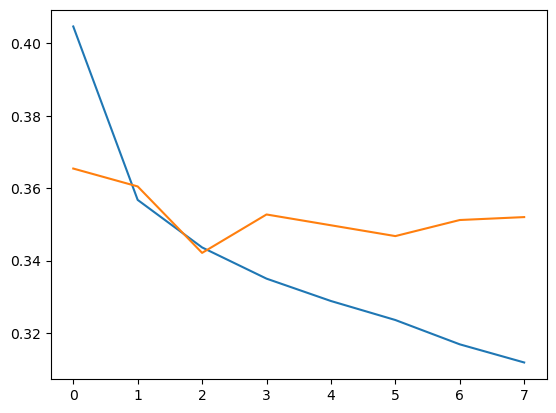

In [30]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

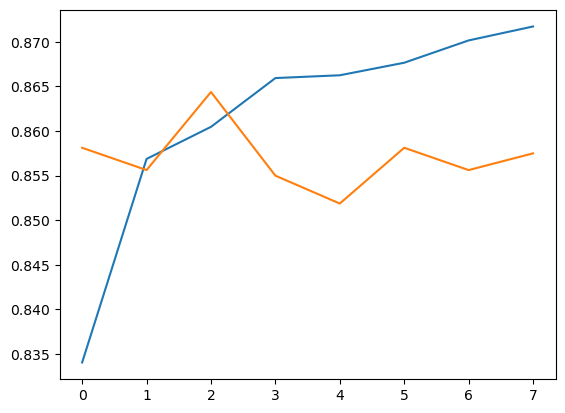

In [31]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])